In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
import platform
import sklearn

from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

sns.set_theme(style="whitegrid")

In [2]:
DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../figures")
LOGS_DIR = Path("../logs")

FIGURES_DIR.mkdir(exist_ok=True)
LOGS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(
    DATA_DIR / "PhiUSIIL_Preprocessed.csv"
)

with open(RESULTS_DIR / "feature_config.json", "r") as f:
    config = json.load(f)

split = np.load(
    RESULTS_DIR / "baseline_split.npz"
)

full_features = config["full_features"]

train_idx = split["train_idx"]
test_idx = split["test_idx"]

print("Dimensi dataset:", df.shape)
print("Jumlah fitur:", len(full_features))
print("Random state:", config["random_state"])
print("Test size:", config["test_size"])

Dimensi dataset: (235370, 56)
Jumlah fitur: 47
Random state: 42
Test size: 0.3


In [3]:
X = df[full_features]

y = df["label"].map({
    0: 1,
    1: 0
})

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

assert set(train_idx).isdisjoint(test_idx)
assert not y.isna().any()

print("X Training:", X_train.shape)
print("X Testing:", X_test.shape)

print("y Training:", y_train.shape)
print("y Testing:", y_test.shape)

X Training: (164759, 47)
X Testing: (70611, 47)
y Training: (164759,)
y Testing: (70611,)


In [4]:
class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
})

class_distribution.index = (
    class_distribution.index.map({
        0: "Legitimate",
        1: "Phishing"
    })
)

class_distribution

,Training,Testing
label,,
Legitimate,94395,40455
Phishing,70364,30156


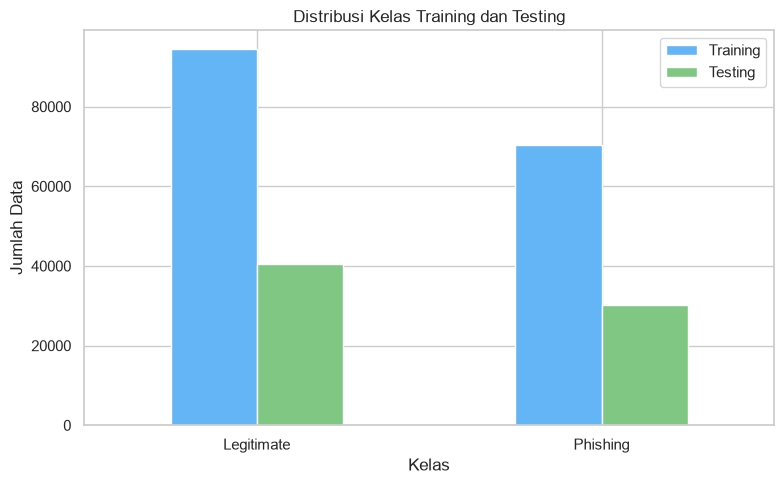

In [5]:
class_distribution.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#64B5F6", "#81C784"]
)

plt.title("Distribusi Kelas Training dan Testing")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [7]:
def evaluate_model(
    model_name,
    model,
    X_train,
    X_test,
    y_train,
    y_test
):

    # Training
    start_train = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_train

    # Prediction
    start_inference = time.perf_counter()

    y_pred = model.predict(X_test)

    inference_time = time.perf_counter() - start_inference

    # Prediction probability
    y_prob = model.predict_proba(X_test)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Evaluation metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time,
        "Inference per Sample (ms)": (
            inference_time / len(X_test)
        ) * 1000,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    return metrics, y_pred, y_prob

In [8]:
results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():

    print(f"Training {model_name}...")

    metrics, y_pred, y_prob = evaluate_model(
        model_name,
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    results.append(metrics)

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    print(f"{model_name} selesai.")
    print("-" * 50)

Training Logistic Regression...
Logistic Regression selesai.
--------------------------------------------------
Training Random Forest...
Random Forest selesai.
--------------------------------------------------


In [9]:
results_df = pd.DataFrame(results)

results_df.round(6)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s),Inference Time (s),Inference per Sample (ms),TN,FP,FN,TP
0,Logistic Regression,0.999278,0.999768,0.998541,0.999154,0.999964,0.390820,0.021930,0.000311,40448,7,44,30112
1,Random Forest,0.999830,0.999867,0.999735,0.999801,0.999998,4.150421,0.072756,0.001030,40451,4,8,30148


In [10]:
for model_name, y_pred in predictions.items():

    print("=" * 60)

    print(model_name)

    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=6,
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

  Legitimate   0.998913  0.999827  0.999370     40455
    Phishing   0.999768  0.998541  0.999154     30156

    accuracy                       0.999278     70611
   macro avg   0.999340  0.999184  0.999262     70611
weighted avg   0.999278  0.999278  0.999278     70611

Random Forest
              precision    recall  f1-score   support

  Legitimate   0.999802  0.999901  0.999852     40455
    Phishing   0.999867  0.999735  0.999801     30156

    accuracy                       0.999830     70611
   macro avg   0.999835  0.999818  0.999826     70611
weighted avg   0.999830  0.999830  0.999830     70611



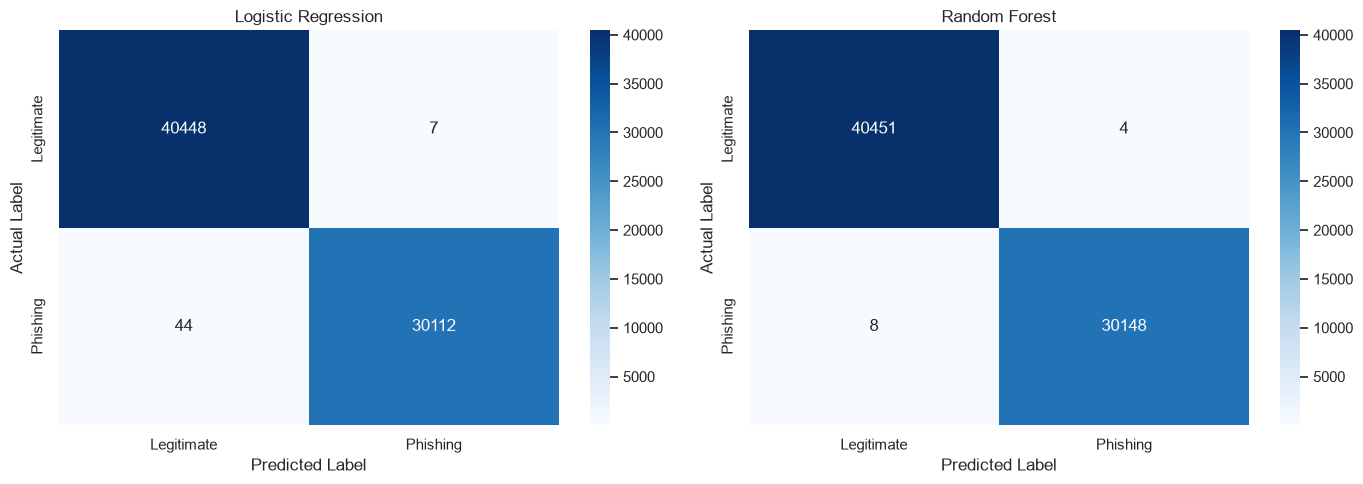

In [11]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

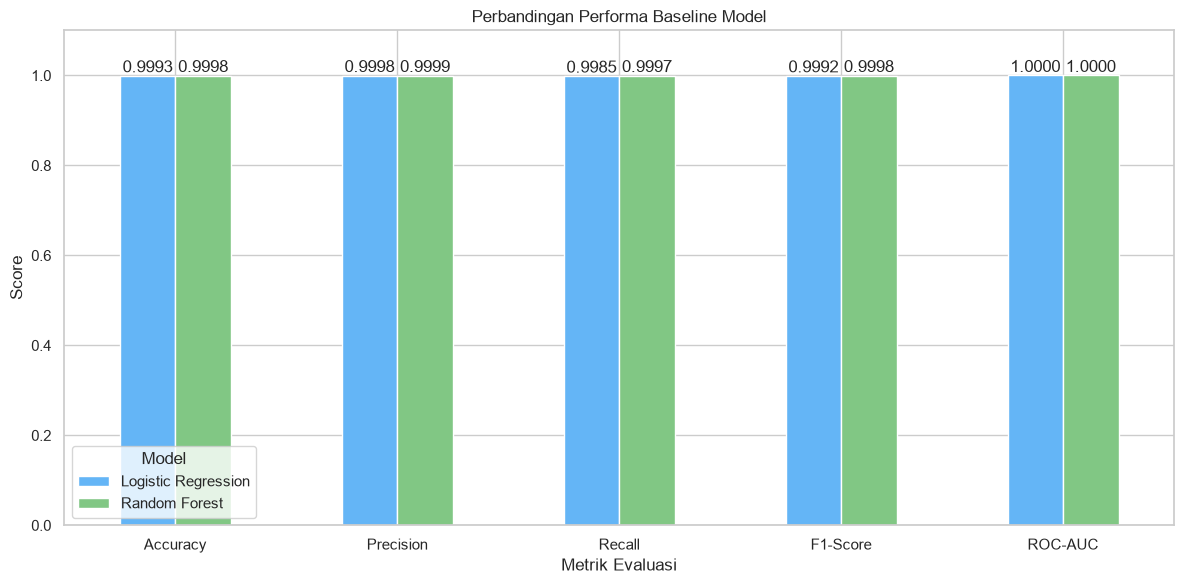

In [12]:
metrics_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

performance_df = (
    results_df
    .set_index("Model")[metrics_columns]
    .T
)

ax = performance_df.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#64B5F6", "#81C784"]
)

plt.title("Perbandingan Performa Baseline Model")
plt.xlabel("Metrik Evaluasi")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

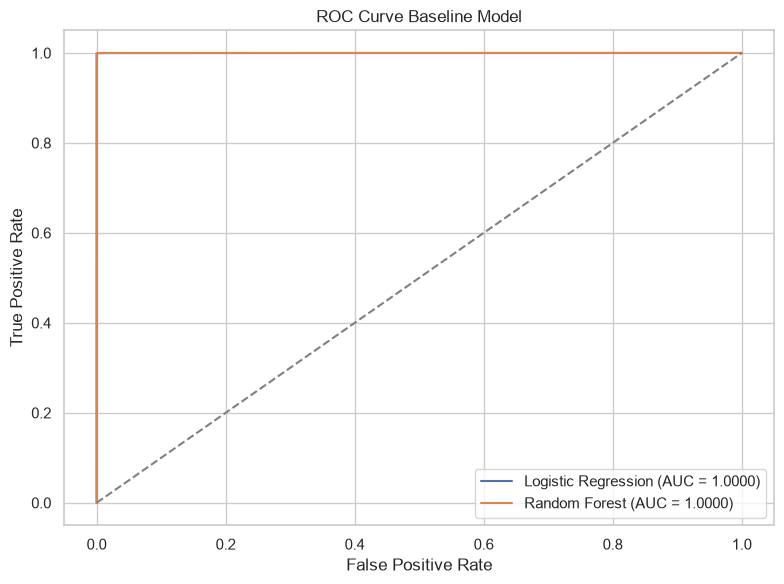

In [13]:
plt.figure(figsize=(8, 6))

for model_name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curve Baseline Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

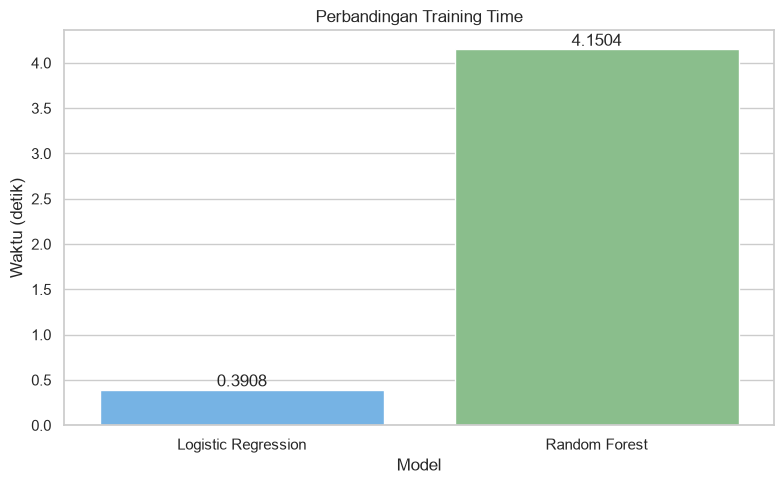

In [14]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time (s)",
    hue="Model",
    palette=["#64B5F6", "#81C784"],
    legend=False
)

plt.title("Perbandingan Training Time")
plt.xlabel("Model")
plt.ylabel("Waktu (detik)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_training_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

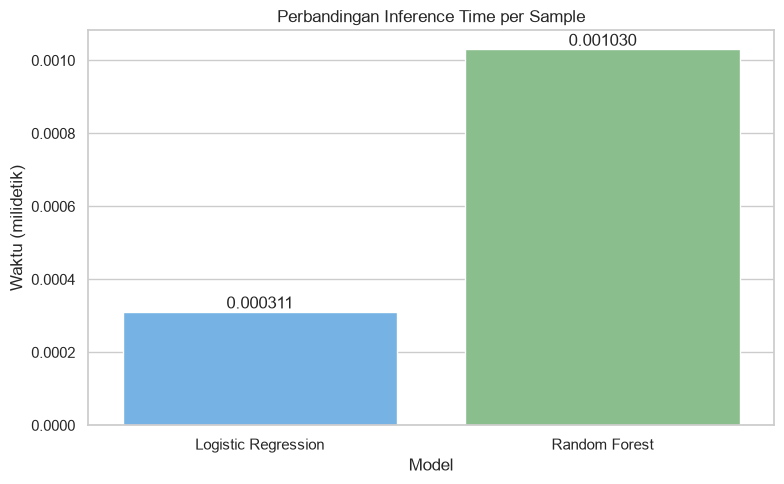

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Inference per Sample (ms)",
    hue="Model",
    palette=["#64B5F6", "#81C784"],
    legend=False
)

plt.title("Perbandingan Inference Time per Sample")
plt.xlabel("Model")
plt.ylabel("Waktu (milidetik)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.6f")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_inference_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
results_df["Scenario"] = "A"
results_df["Feature Type"] = "Full Features"
results_df["Validation"] = "Random Split"
results_df["Number of Features"] = len(full_features)
results_df["Training Samples"] = len(X_train)
results_df["Testing Samples"] = len(X_test)
results_df["Random State"] = 42

results_df.to_csv(
    RESULTS_DIR / "baseline_metrics.csv",
    index=False
)

print("Hasil baseline berhasil disimpan.")

Hasil baseline berhasil disimpan.


In [17]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Model dengan F1-Score tertinggi:")
print("Model:", best_model["Model"])

print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])
print("ROC-AUC:", best_model["ROC-AUC"])

Model dengan F1-Score tertinggi:
Model: Random Forest
Accuracy: 0.9998300548073247
Precision: 0.9998673388166622
Recall: 0.9997347128266348
F1-Score: 0.9998010214233601
ROC-AUC: 0.9999984688034859
